# Deepfake Detection Project
## Exploratory Data Analysis

This notebook examines the cleaned Celeb-DF V2-derived image dataset after leakage-safe train, validation, and test partitions were created.

## 1. Class and Split Distribution

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

DATA_ROOT = Path("../data/Celeb_V2")

manifest = pd.read_csv(
    "../data/celeb_df_clean_manifest.csv"
)

manifest.head()

,path,filename,label,split,video_id,identity,original_split,group_key,clean_split
0,..\data\Celeb_V2\Train\real\00000_face_0.jpg,00000_face_0.jpg,real,train,00000,NaN,train,real_00000,train
1,..\data\Celeb_V2\Train\real\00000_face_1.jpg,00000_face_1.jpg,real,train,00000,NaN,train,real_00000,train
2,..\data\Celeb_V2\Train\real\00000_face_10.jpg,00000_face_10.jpg,real,train,00000,NaN,train,real_00000,train
3,..\data\Celeb_V2\Train\real\00000_face_11.jpg,00000_face_11.jpg,real,train,00000,NaN,train,real_00000,train
4,..\data\Celeb_V2\Train\real\00000_face_12.jpg,00000_face_12.jpg,real,train,00000,NaN,train,real_00000,train


In [2]:
print(pd.crosstab(
    manifest["clean_split"],
    manifest["label"]
))

label         fake   real
clean_split              
test          5179   5020
train        40619  40375
val           4873   4965


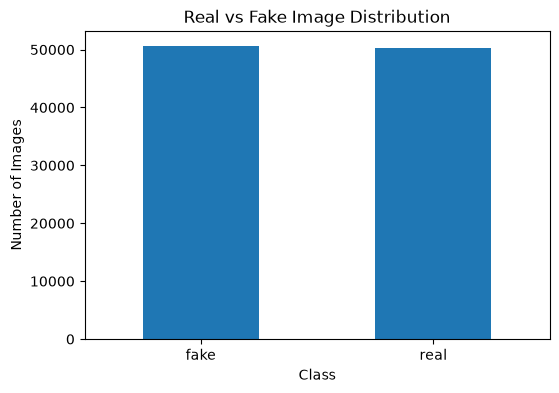

In [3]:
class_counts = manifest["label"].value_counts()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")

plt.title("Real vs Fake Image Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

The dataset is approximately balanced between real and fake facial images, which reduces the risk of a model achieving high accuracy simply by favoring the majority class.

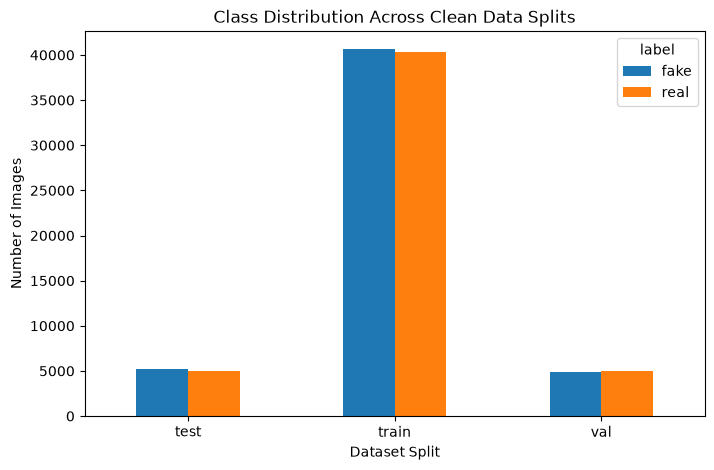

In [4]:
split_counts = pd.crosstab(
    manifest["clean_split"],
    manifest["label"]
)

split_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Class Distribution Across Clean Data Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

### Interpretation

The cleaned dataset remains approximately balanced between real and fake images across the training, validation, and test partitions. This is desirable because it reduces class imbalance and allows metrics such as accuracy to be interpreted more reliably.

## 2. Image Dimension and Integrity Checks

In [5]:
sample_paths = manifest["path"].sample(
    1000,
    random_state=42
)

dimensions = []

for path in sample_paths:
    with Image.open(path) as img:
        dimensions.append(img.size)

dimension_counts = pd.Series(dimensions).value_counts()

print(dimension_counts.head())

(256, 256)    1000
Name: count, dtype: int64


### Image Dimension Check

A random sample of 1,000 images was examined, and all sampled images had dimensions of 256 × 256 pixels. This is consistent with the documented preprocessing of the dataset and means the images can be provided to the neural network using a consistent input size.

In [9]:
corrupted_files = []

for path in manifest["path"]:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        corrupted_files.append(path)

print("Number of corrupted images:", len(corrupted_files))

Number of corrupted images: 0


### Image Integrity Check

All image files referenced by the clean manifest were tested for readability. No corrupted images were detected, so no files needed to be removed before model training.

In [21]:
missing_paths = [
    path for path in manifest["path"]
    if not Path(path).exists()
]

print("Missing image paths:", len(missing_paths))

Missing image paths: 0


## 3. Visual Inspection of Real and Fake Images

In [14]:
real_samples = manifest[
    manifest["label"] == "real"
].sample(8, random_state=42)

fake_samples = manifest[
    manifest["label"] == "fake"
].sample(8, random_state=42)

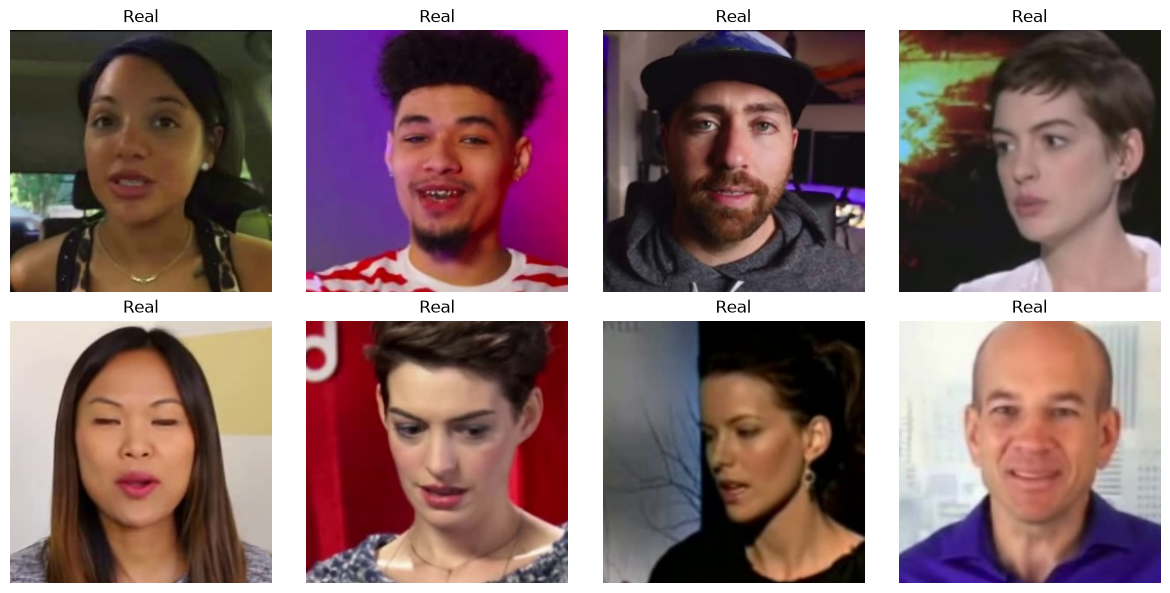

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flatten(), real_samples.iterrows()):
    img = Image.open(row["path"])
    ax.imshow(img)
    ax.set_title("Real")
    ax.axis("off")

plt.tight_layout()
plt.show()

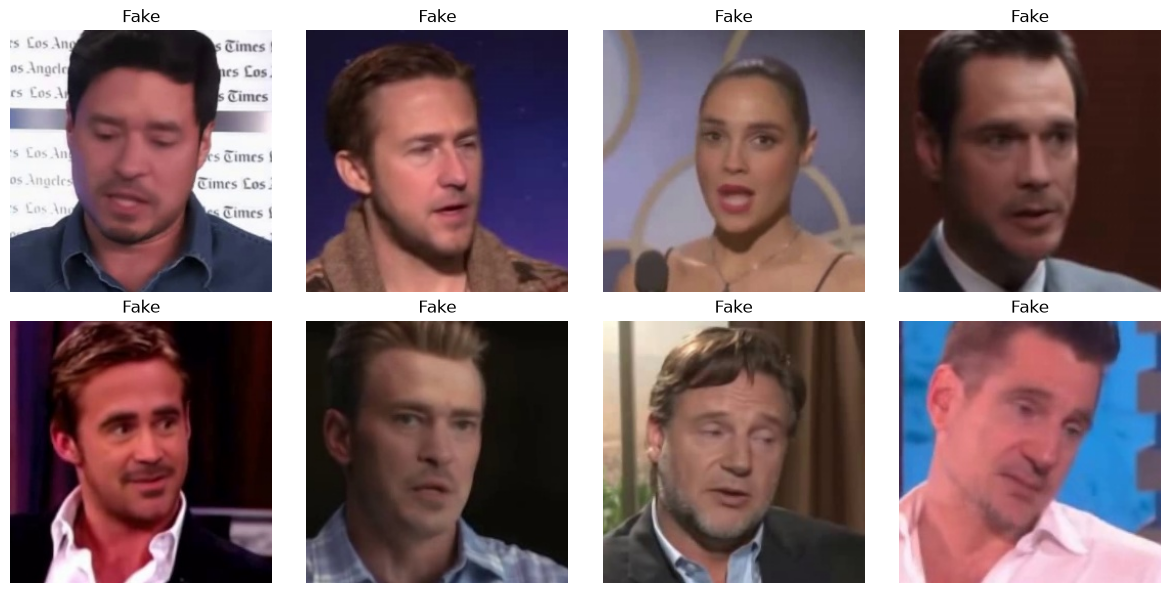

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flatten(), fake_samples.iterrows()):
    img = Image.open(row["path"])
    ax.imshow(img)
    ax.set_title("Fake")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
sample_modes = []

for path in manifest["path"].sample(1000, random_state=42):
    with Image.open(path) as img:
        sample_modes.append(img.mode)

pd.Series(sample_modes).value_counts()

RGB    1000
Name: count, dtype: int64

### Visual Inspection

Random real and fake facial images were visually inspected. Both classes contain cropped facial regions at a consistent resolution. Although some visual differences may be noticeable in individual samples, visual inspection alone is not sufficient to reliably determine whether an image is manipulated. The deep-learning models will therefore be used to learn more subtle spatial and texture patterns.

## 4. Pixel Intensity Analysis

In [17]:
def mean_pixel_intensity(path):
    with Image.open(path).convert("RGB") as img:
        arr = np.array(img)
        return arr.mean()

real_intensity = (
    manifest[manifest["label"] == "real"]
    .sample(500, random_state=42)["path"]
    .apply(mean_pixel_intensity)
)

fake_intensity = (
    manifest[manifest["label"] == "fake"]
    .sample(500, random_state=42)["path"]
    .apply(mean_pixel_intensity)
)

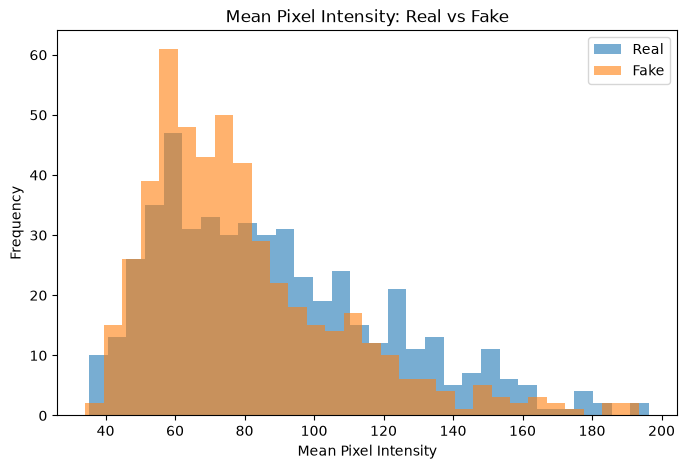

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    real_intensity,
    bins=30,
    alpha=0.6,
    label="Real"
)

plt.hist(
    fake_intensity,
    bins=30,
    alpha=0.6,
    label="Fake"
)

plt.title("Mean Pixel Intensity: Real vs Fake")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [23]:
intensity_summary = pd.DataFrame({
    "Real": real_intensity.describe(),
    "Fake": fake_intensity.describe()
})

intensity_summary

,Real,Fake
count,500.000000,500.000000
mean,88.182768,79.468160
std,32.905323,28.329826
min,35.259593,34.183609
25%,61.447055,58.888429
50%,82.481351,72.703580
75%,109.001748,92.004100
max,196.390498,193.598007


In [24]:
print("Mean pixel intensity - Real:",
      round(real_intensity.mean(), 2))

print("Mean pixel intensity - Fake:",
      round(fake_intensity.mean(), 2))

Mean pixel intensity - Real: 88.18
Mean pixel intensity - Fake: 79.47


### Pixel Intensity Interpretation

The distributions of mean pixel intensity were compared for a random sample of real and fake images. This analysis is intended as a preprocessing sanity check rather than as evidence of deepfake characteristics. Any observed differences could result from lighting, source-video properties, compression, or preprocessing rather than manipulation itself.

In [25]:
video_counts = (
    manifest
    .groupby(["clean_split", "label"])["video_id"]
    .nunique()
    .unstack()
)

video_counts

label,fake,real
clean_split,,
test,578,89
train,4519,711
val,542,89


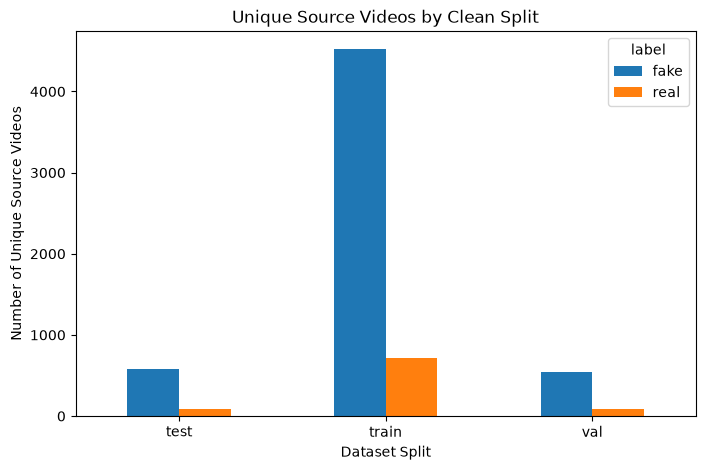

In [26]:
video_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Unique Source Videos by Clean Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Unique Source Videos")
plt.xticks(rotation=0)
plt.show()

## EDA Summary

The cleaned Celeb-DF V2-derived dataset contains approximately 101,000 facial images and remains well balanced between real and fake classes.

The training, validation, and test partitions are also approximately balanced. A sample of the images confirmed the expected 256 × 256 resolution, and no corrupted image files were detected.

Visual inspection confirmed that the dataset contains consistently cropped facial regions. Pixel-intensity analysis was performed as a basic preprocessing sanity check and was not interpreted as evidence of manipulation.

The dataset therefore appears suitable for the next phase of the project: development of a baseline Convolutional Neural Network.